In [1]:
import sys
print(sys.executable)

import pandas as pd
import sklearn

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

C:\Users\hp\Desktop\kubernetes-monitoring-dashboard\venv\Scripts\python.exe
Pandas: 3.0.6
Scikit-learn: 1.9.1


In [2]:
from sklearn.preprocessing import StandardScaler

spending_map = {
    "Low": 1,
    "Average": 2,
    "High": 3
}

df_clean["Spending_Score_Num"] = df_clean["Spending_Score"].map(spending_map)

features = [
    "Age",
    "Work_Experience",
    "Family_Size",
    "Spending_Score_Num"
]

X = df_clean[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", features)
print("Scaled data shape:", X_scaled.shape)
print("\nFirst 5 scaled rows:")
print(X_scaled[:5])

NameError: name 'df_clean' is not defined

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv(
    r"C:\Users\hp\Desktop\OIBSIP\DataAnalytics-L1-CustomerSegmentation\Train.csv"
)

# Clean dataset
df_clean = df.copy()

categorical_cols = ["Ever_Married", "Graduated", "Profession", "Var_1"]
for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

numerical_cols = ["Work_Experience", "Family_Size"]
for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Convert spending score into numbers
spending_map = {"Low": 1, "Average": 2, "High": 3}
df_clean["Spending_Score_Num"] = df_clean["Spending_Score"].map(spending_map)

# Select features
features = ["Age", "Work_Experience", "Family_Size", "Spending_Score_Num"]
X = df_clean[features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset loaded and cleaned successfully!")
print("Missing values:", df_clean[features].isnull().sum().sum())
print("Scaled data shape:", X_scaled.shape)
print("\nFirst 5 scaled rows:")
print(X_scaled[:5])

Dataset loaded and cleaned successfully!
Missing values: 0
Scaled data shape: (8068, 4)

First 5 scaled rows:
[[-1.28462344 -0.45113599  0.76269849 -0.7368331 ]
 [-0.32715082 -0.45113599  0.09580227  0.61241099]
 [ 1.40826831 -0.45113599 -1.23799017 -0.7368331 ]
 [ 1.40826831 -0.7574104  -0.57109395  1.96165509]
 [-0.20746674 -0.45113599  2.09649094  1.96165509]]


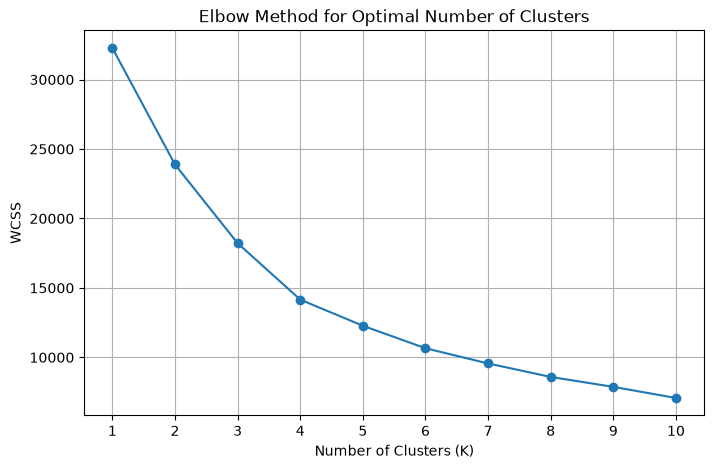

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [5]:
from sklearn.cluster import KMeans

# Create 4 customer clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer clustering completed!")
print("\nCustomers in each cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

print("\nFirst 5 customer records:")
print(df_clean[["Age", "Gender", "Spending_Score", "Cluster"]].head())

Customer clustering completed!

Customers in each cluster:
Cluster
0    1938
1    2031
2    2590
3    1509
Name: count, dtype: int64

First 5 customer records:
   Age  Gender Spending_Score  Cluster
0   22    Male            Low        0
1   38  Female        Average        2
2   67  Female            Low        1
3   67    Male           High        2
4   40  Female           High        2


In [6]:
# Analyze customer profiles in each cluster
cluster_summary = df_clean.groupby("Cluster")[
    ["Age", "Work_Experience", "Family_Size", "Spending_Score_Num"]
].mean().round(2)

print("Customer Profile by Cluster:")
print(cluster_summary)

print("\nSpending Score Distribution by Cluster:")
print(pd.crosstab(
    df_clean["Cluster"],
    df_clean["Spending_Score"],
    normalize="index"
).round(2) * 100)

Customer Profile by Cluster:
           Age  Work_Experience  Family_Size  Spending_Score_Num
Cluster                                                         
0        28.43             1.13         4.26                1.08
1        49.54             0.97         1.62                1.00
2        53.79             1.18         2.99                2.43
3        36.89             8.44         2.48                1.36

Spending Score Distribution by Cluster:
Spending_Score  Average  High    Low
Cluster                             
0                   7.0   0.0   92.0
1                   0.0   0.0  100.0
2                  56.0  43.0    0.0
3                  24.0   6.0   70.0


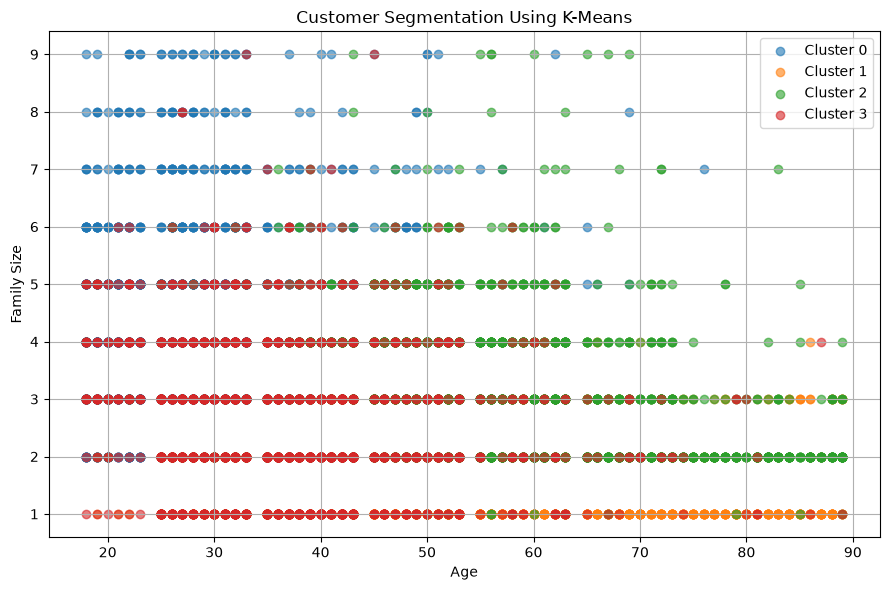

In [7]:
plt.figure(figsize=(9, 6))

for cluster in sorted(df_clean["Cluster"].unique()):
    cluster_data = df_clean[df_clean["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Age"],
        cluster_data["Family_Size"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Age")
plt.ylabel("Family Size")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

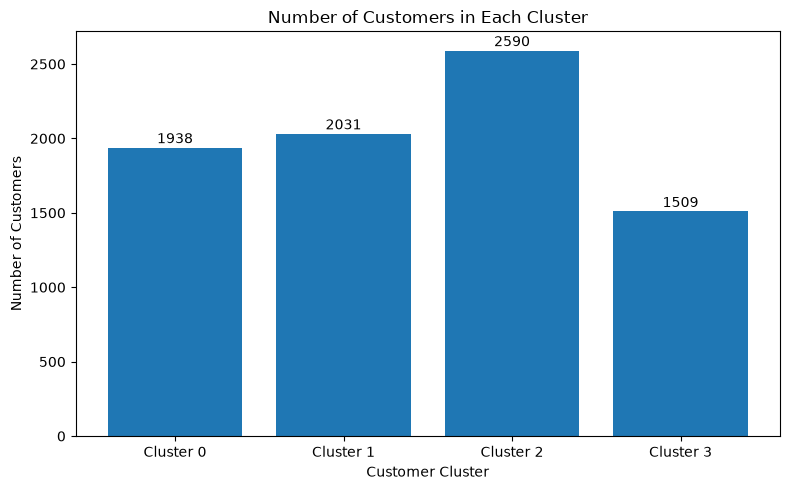

In [8]:
cluster_counts = df_clean["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.xticks([0, 1, 2, 3], ["Cluster 0", "Cluster 1", "Cluster 2", "Cluster 3"])

for i, count in enumerate(cluster_counts.values):
    plt.text(i, count + 30, str(count), ha="center")

plt.tight_layout()
plt.show()

In [9]:
print("CUSTOMER SEGMENTATION - PROJECT SUMMARY")
print("=" * 45)

print(f"Total customers analyzed: {len(df_clean)}")
print(f"Number of clusters: {df_clean['Cluster'].nunique()}")

print("\nCustomer count by cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

print("\nKey Findings:")
print("1. Cluster 0: Younger customers with mostly low spending scores.")
print("2. Cluster 1: Older customers with low spending scores.")
print("3. Cluster 2: Customers with average or high spending scores.")
print("4. Cluster 3: Customers with higher average work experience.")

print("\nConclusion:")
print("K-Means clustering grouped customers into four segments")
print("based on age, work experience, family size, and spending score.")
print("These segments can help businesses plan targeted marketing")
print("and personalized customer engagement strategies.")

CUSTOMER SEGMENTATION - PROJECT SUMMARY
Total customers analyzed: 8068
Number of clusters: 4

Customer count by cluster:
Cluster
0    1938
1    2031
2    2590
3    1509
Name: count, dtype: int64

Key Findings:
1. Cluster 0: Younger customers with mostly low spending scores.
2. Cluster 1: Older customers with low spending scores.
3. Cluster 2: Customers with average or high spending scores.
4. Cluster 3: Customers with higher average work experience.

Conclusion:
K-Means clustering grouped customers into four segments
based on age, work experience, family size, and spending score.
These segments can help businesses plan targeted marketing
and personalized customer engagement strategies.
